# Question 2 — Motion or Memory?
Hasan Amjad (25280042)

In [1]:
%load_ext autoreload
%autoreload 2
import platform, time, torch
from q2.common import *
from q2.transforms import *
from q2.models import *

DEVICE = get_device()
print("torch", torch.__version__, "| device:", DEVICE, "|", platform.platform(), platform.processor())

torch 2.15.0 | device: mps | macOS-27.0.1-arm64-arm-64bit arm


## 1. Setup
### Table 1 — checks

In [2]:
from q2.checks import run_table1, print_table1
table1 = run_table1()
print_table1(table1)
save_json(table1, "table1.json");

    Check                                      Expected                                Yours
(a) max|M(M(x)) - x|                           0                                       0 (torch.equal: True)  [OK ]
(b) max|R^4(x) - x|                            0                                       0 (torch.equal: True)  [OK ]
(c) max|M R M(x) - R^-1(x)|                    0                                       0 (torch.equal: True)  [OK ]
(d) bright pixel of M(p) (frame, row, column)  (7, 10, 43)                             (7, 10, 43)  [OK ]
(e) bright pixel of R(p) (frame, row, column)  (7, 43, 10)                             (7, 43, 10)  [OK ]
(f) 1x input / target frames                   1, 2, 3, 4, 5 / 6, 7, 8, 9, 10          1, 2, 3, 4, 5 / 6, 7, 8, 9, 10  [OK ]
(g) 2x input / target frames                   1, 3, 5, 7, 9 / 11, 13, 15, 17, 19      1, 3, 5, 7, 9 / 11, 13, 15, 17, 19  [OK ]
(h) 3x input / target frames                   1, 4, 7, 10, 13 / 16, 19                1, 4, 

### Data

In [3]:
data = load_moving_mnist()
train_u8, val_u8, test_u8 = splits(data)
print("all", tuple(data.shape), data.dtype, "| train", len(train_u8), "| val", len(val_u8), "| test", len(test_u8))

all (10000, 20, 1, 64, 64) torch.uint8 | train 8000 | val 1000 | test 1000


### Figure 1 — training-data motion

pairs = 950, pixels kept = 103,050, median speed = 3.32 px/frame
2x -> 6.635 px/frame;  3x -> 9.953 px/frame
direction fractions per 20-degree bin: [0.049, 0.0488, 0.0675, 0.0731, 0.0602, 0.0561, 0.0263, 0.0326, 0.0384, 0.082, 0.0642, 0.0541, 0.0666, 0.0614, 0.0571, 0.0366, 0.0487, 0.0772]


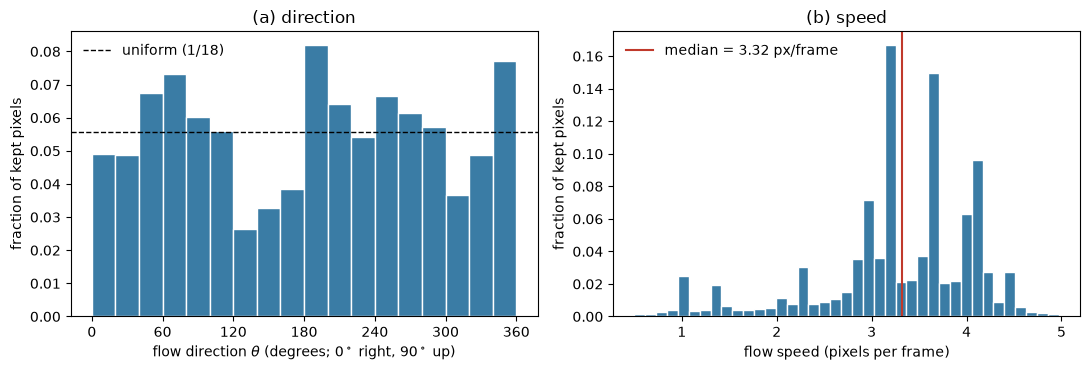

In [4]:
from q2.flow import pooled_flow, figure1
dx, dy, n_pairs = pooled_flow(train_u8, n_videos=50)
fig, fig1_stats = figure1(dx, dy, FIG_DIR / "fig1_flow_stats.png")
fig1_stats["n_pairs"] = n_pairs
save_json(fig1_stats, "fig1_stats.json")
print(f"pairs = {n_pairs}, pixels kept = {fig1_stats['n_pixels']:,}, median speed = {fig1_stats['median_speed']:.3g} px/frame")
print("2x ->", round(2*fig1_stats['median_speed'], 3), "px/frame;  3x ->", round(3*fig1_stats['median_speed'], 3), "px/frame")
print("direction fractions per 20-degree bin:", fig1_stats["direction_fractions"])

### Model A — parameter count

In [5]:
mA = model_A()
print("model A params:", n_params(mA))
assert n_params(mA) == 480_784
with torch.no_grad():
    out = mA(torch.rand(2, 5, 1, 64, 64))
print("output shape:", tuple(out.shape))

model A params: 480784
output shape: (2, 5, 1, 64, 64)


## 2. Baseline: ConvLSTM
Training: `python -m q2.train --model A` (seeds 0, 1).

A s0: final val E(5) 2.247e-02, mean epoch 24.8s
A s1: final val E(5) 2.154e-02, mean epoch 26.4s


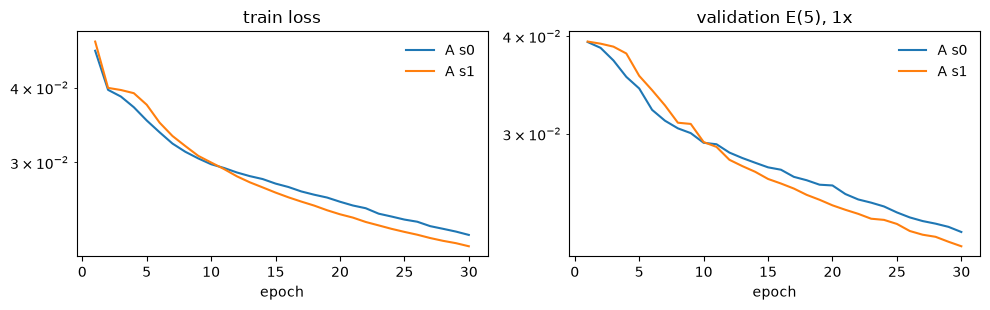

In [6]:
import matplotlib.pyplot as plt

def plot_training(names, seeds=(0, 1), path=None):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    for n in names:
        for s in seeds:
            h = load_json(f"train_{n}_s{s}.json")
            ep = range(1, len(h["train_loss"]) + 1)
            ax[0].plot(ep, h["train_loss"], label=f"{n} s{s}")
            ax[1].plot(ep, h["val_e5"], label=f"{n} s{s}")
            print(f"{n} s{s}: final val E(5) {h['val_e5'][-1]:.3e}, mean epoch {h['mean_epoch_time']:.1f}s")
    for a, t in zip(ax, ["train loss", "validation E(5), 1x"]):
        a.set_xlabel("epoch"); a.set_title(t); a.set_yscale("log"); a.legend(frameon=False)
    fig.tight_layout()
    if path: fig.savefig(path, dpi=150, bbox_inches="tight")

plot_training(["A"], path=FIG_DIR / "training_A.png")

In [7]:
import numpy as np, pandas as pd
from q2.evaluate import *
from q2 import visuals as V

W = test_windows(test_u8)
X1, Y1, _ = W[1]
SEEDS = (0, 1)
res, pv, preds = {}, {}, {}
for name, mdl in [("Blank", Blank()), ("Copy-last", CopyLast())]:
    res[name], pv[name], preds[name] = evaluate(mdl.to(DEVICE), W)
for sd in SEEDS:
    res[f"A_s{sd}"], pv[f"A_s{sd}"], preds[f"A_s{sd}"] = evaluate(load_model("A", sd), W)
save_json(res, "metrics_A.json")

PosixPath('/Users/hasanamjad/Documents/MS AI/AI 651 DL Time Space/DL4STG_PA2 2/Question2/results/metrics_A.json')

### Table 2

In [8]:
def vals(name, key):
    return [res[f"{name}_s{s}"][key] for s in SEEDS] if f"{name}_s0" in res else [res[name][key]]

rows = {}
for name, params in [("A", n_params(model_A())), ("Blank", 0), ("Copy-last", 0)]:
    r = {f"MSE{h+1}": cell([v[h] for v in vals(name, "MSE_h")]) for h in range(5)}
    r["E(5)"] = cell(vals(name, "E5_1x")); r["params"] = f"{params:,}"
    rows[name] = r
table2 = pd.DataFrame(rows).T; table2

,MSE1,MSE2,MSE3,MSE4,MSE5,E(5),params
A,"0.0172 (0.0176, 0.0167)","0.0205 (0.021, 0.02)","0.0228 (0.0233, 0.0222)","0.0244 (0.025, 0.0238)","0.026 (0.0266, 0.0255)","0.0222 (0.0227, 0.0216)","480,784"
Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


### Figure 2

videos: [9191, 9007, 9012] overlap scores: [0.657 1.    1.   ]


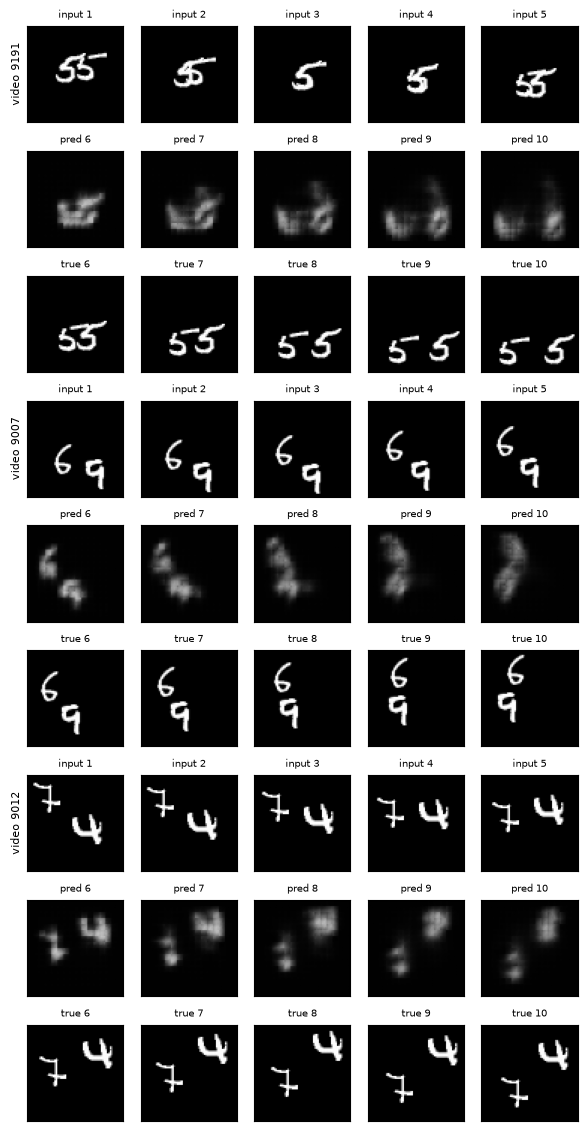

In [9]:
vt = to_float(test_u8)
n_ov = [V.overlap_frames(vt[i], range(1, 6)) for i in range(len(vt))]
merge_then_split = [i for i in range(len(vt)) if n_ov[i] >= 3 and V.separated(vt[i], [9, 10])]
fig2_ids = [max(merge_then_split, key=lambda i: n_ov[i])] + [i for i in range(len(vt)) if V.overlap_frames(vt[i], range(1, 11)) == 0][:2]
print("videos:", [9000 + i for i in fig2_ids])
V.figure2(X1, Y1, preds["A_s0"]["I"], fig2_ids, FIG_DIR / "fig2_A_predictions.png");

## 3. Testing the baseline
### Table 3

In [10]:
rows = {}
for name in ["A", "Blank", "Copy-last"]:
    rows[name] = {k: cell(vals(name, key)) for k, key in
                  [("E(5)", "E5_1x"), ("C_M", "C_M"), ("E_M", "E_M"), ("C_R", "C_R"), ("E_R", "E_R")]}
table3 = pd.DataFrame(rows).T; table3

,E(5),C_M,E_M,C_R,E_R
A,"0.0222 (0.0227, 0.0216)","0.00176 (0.00158, 0.00195)","0.0228 (0.0233, 0.0223)","0.00289 (0.0026, 0.00318)","0.0239 (0.0242, 0.0236)"
Blank,0.0426,0,0.0426,0,0.0426
Copy-last,0.0641,0,0.0641,0,0.0641


### Figure 3

{'C_M': [980, 269], 'C_R': [925, 513]}


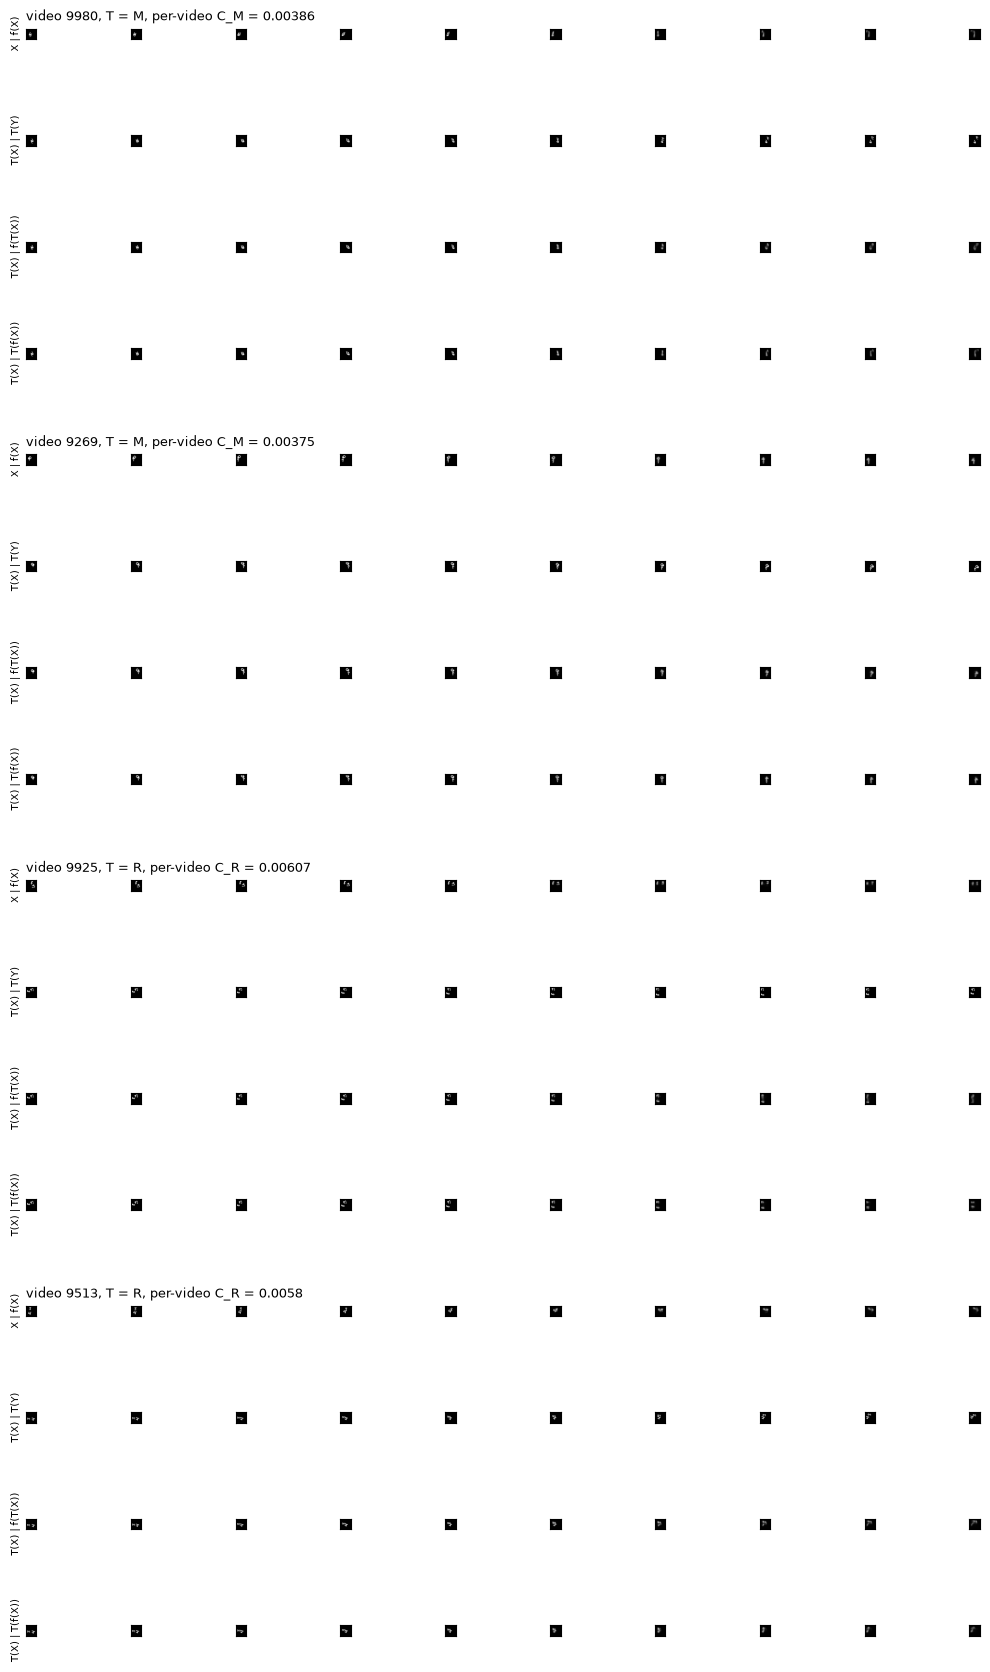

In [11]:
p0, P0 = pv["A_s0"], preds["A_s0"]
marks = {"C_M": np.argsort(-p0["C_M"])[:2].tolist(), "C_R": np.argsort(-p0["C_R"])[:2].tolist()}
for key, T in [("C_M", mirror), ("C_R", rotate)]:
    for n, i in enumerate(marks[key]):
        rows4 = V.four_rows(X1[i], Y1[i], P0["I"][i], P0[key[-1]][i], T)
        label = f"video {9000+i}, T = {key[-1]}, per-video {key} = {fmt(float(p0[key][i]))}"
        V.figure3_panel(rows4, label, FIG_DIR / f"fig3_A_{key[-1]}{n+1}_video{9000+i}.png")
        V.gif(rows4, GIF_DIR / f"fig3_A_{key[-1]}_video{9000+i}.gif")
print(marks)

### Figure 4

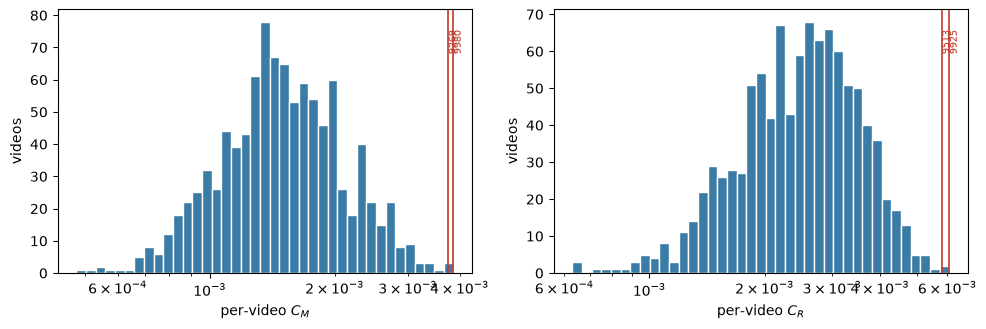

In [12]:
V.figure4(p0, marks, FIG_DIR / "fig4_A_consistency_hist.png");

### Table 4

In [13]:
rows = {}
for name in ["A", "Copy-last"]:
    rows[name] = {"E(2) 1x": cell(vals(name, "E2_1x")), "E(2) 2x": cell(vals(name, "E2_2x")),
                  "E(2) 3x": cell(vals(name, "E2_3x")), "E(5) 1x": cell(vals(name, "E5_1x")),
                  "E(5) 2x": cell(vals(name, "E5_2x"))}
table4 = pd.DataFrame(rows).T; table4

,E(2) 1x,E(2) 2x,E(2) 3x,E(5) 1x,E(5) 2x
A,"0.0189 (0.0193, 0.0184)","0.0444 (0.0431, 0.0457)","0.0522 (0.0511, 0.0533)","0.0222 (0.0227, 0.0216)","0.0488 (0.0467, 0.0509)"
Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719


### Figure 5

video 9002


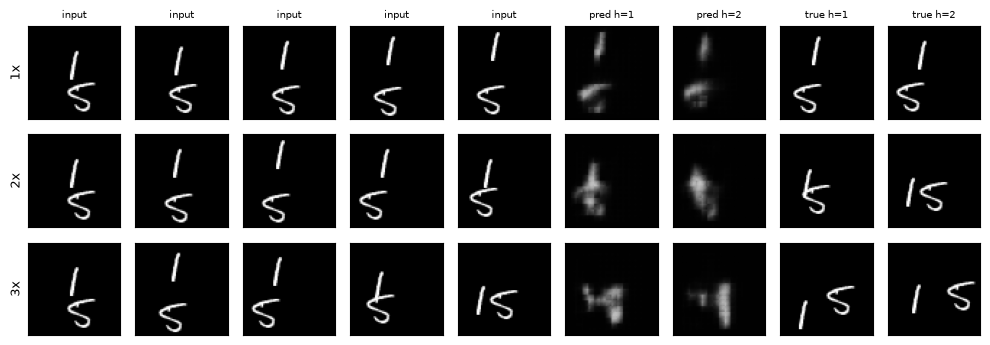

In [14]:
true_frames = [6, 7, 11, 13, 16, 19]
cands = [i for i in range(len(vt)) if V.separated(vt[i], true_frames)]
strict = [i for i in cands if V.separated(vt[i], range(1, 20))]
fig5_id = (strict or cands)[0]
print("video", 9000 + fig5_id, "| digits apart in all frames:", fig5_id in strict)
V.figure5(W, preds["A_s0"], fig5_id, FIG_DIR / "fig5_A_speed.png")
save_json({"fig2_ids": fig2_ids, "fig3_marks": marks, "fig5_id": fig5_id}, "figure_videos.json");